## Бизнес-анализ потребления электроэнергии сталелитейного завода

**Данные:** DAEWOO Steel Co. Ltd (Кванъян, Республика Корея), 01.01.2018 – 31.12.2018.
**Объём:** 35 040 записей с шагом 15 минут, 11 столбцов.

### Опорные показатели

| Показатель | Значение |
|---|---|
| Потребление за год | **959 637 кВт·ч** |
| Счёт за год (все статьи) | **199,5 млн вон** (≈ 181 тыс. долл. при 1100 вон/долл.) |
| Максимум 15-минутной мощности | **628,7 кВт** |
| Средний коэффициент мощности (cos φ) | **86,6%** при нормативе 90% |
| Выбросы CO₂ за год | **403,8 т** |
| Подтверждённый резерв экономии | **13,6 млн вон в год (6,8% счёта)** |

### План разбора

| № | Шаг | Вопрос заказчика |
|---|---|---|
| 1 | Тарифная модель | Из чего складывается счёт завода? |
| 2 | Реактивная мощность и cos φ | Сколько переплачиваем за низкий cos φ? |
| 3 | Пики и тарифные зоны суток | Где переплачиваем за время потребления? |
| 4 | Качество метки нагрузки | Можно ли верить штатной классификации? |
| 5 | Углеродный след | Что можно и чего нельзя сказать про CO₂? |
| 6 | Сводка | Каков подтверждённый резерв экономии? |

## Справочник: что означают столбцы данных

| Столбец | Простыми словами |
|---|---|
| `date` | Момент замера. Шаг — 15 минут, без пропусков |
| `Usage_kWh` | **Активная энергия** за 15 минут, кВт·ч — та, что совершает полезную работу (нагрев, движение). Средняя **мощность** интервала в кВт = значение × 4 (в интервале 0,25 часа) |
| `Lagging_Current_Reactive.Power_kVarh` | **Индуктивная (отстающая) реактивная энергия** за интервал. Её «перекачивают» электродвигатели, трансформаторы, индукционные печи: работы не совершает, но загружает провода и трансформаторы |
| `Leading_Current_Reactive_Power_kVarh` | **Ёмкостная (опережающая) реактивная энергия**: конденсаторы, длинные кабели. Тоже «паразитная», но со знаком плюс для компенсации индуктивной |
| `Lagging/Leading_Current_Power_Factor` | Коэффициент мощности (cos φ) в процентах для того типа реактивной мощности, который активен в интервале; второй столбец в этот момент всегда равен 100 |
| `CO2(tCO2)` | Тонны CO₂, приходящиеся на потребление интервала. В этом датасете — расчётная производная от потребления (шаг 5) |
| `NSM` | Секунды от полуночи: техническое поле времени, удобное для моделей |
| `WeekStatus`, `Day_of_week` | Будни/выходные и день недели |
| `Load_Type` | Класс нагрузки, присвоенный системой учёта: лёгкая / средняя / максимальная. **Метка ненадёжна** — см. шаг 4 |

### Три вида мощности

Представьте стакан пива: **пиво** — активная мощность (делает работу),
**пена** — реактивная (место занимает, пользы нет), **весь стакан** — полная
мощность, за которую приходится держать провода и трансформаторы.
Отношение «пива к стакану» и есть **cos φ**.

## Шаг 1: Тарифная модель и структура счёта

**Что делаем:** загружаем данные; назначаем каждой записи тарифную зону суток
и сезон; считаем стоимость энергии; считаем плату за заявленную мощность.

**Пояснения к показателям шага:**

- **Тарифные зоны суток.** Сеть дороже всего содержать в часы всеобщего пика,
  поэтому цена зависит от времени: **пиковая** (11–12, 13–17) — самая дорогая,
  **полупиковая** (9–11, 12–13, 17–23) — средняя, **ночная** (23–09) — дешёвая.
- **Сезоны.** Зимой и летом нагрузка сети выше (отопление, кондиционеры),
  тарифы отличаются от весны и осени.
- **Плата за заявленную мощность (абонентская плата за мощность).** Сеть должна
  быть готова выдать заводу его максимум в любой момент, поэтому отдельно
  оплачивается **максимальная 15-минутная мощность месяца** (кВт) по ставке
  8 320 вон/кВт в месяц. Один неудачный час в месяце увеличивает плату
  за весь месяц.
- **Мощность интервала.** Поскольку `Usage_kWh` — энергия за 15 минут,
  средняя мощность интервала = `Usage_kWh × 4` кВт.

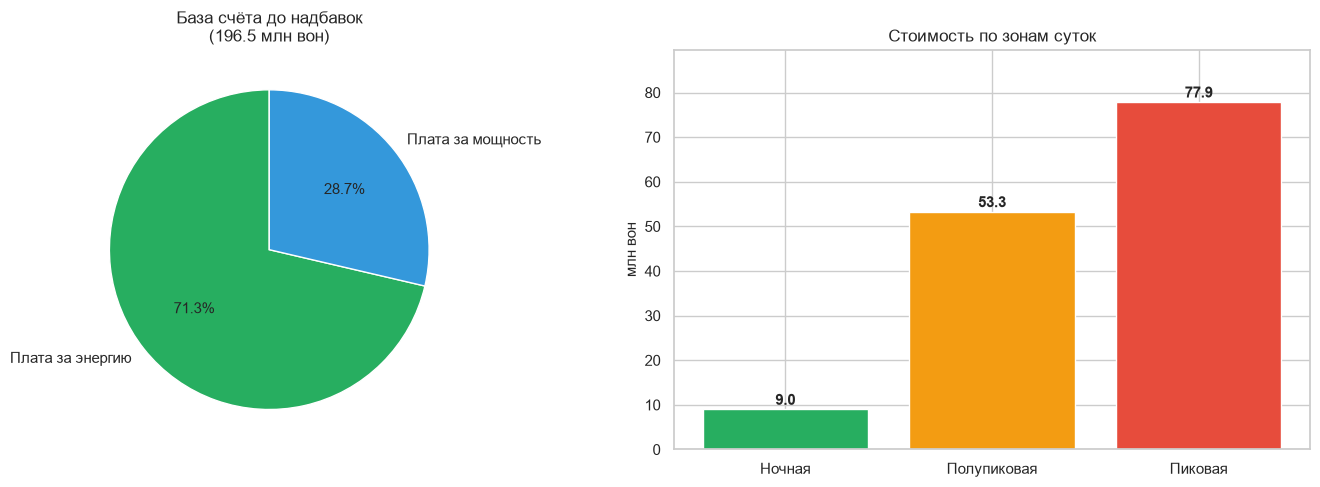

Потребление за год, кВт·ч:           959,637
Максимум 15-мин мощности, кВт:         628.7
Средний месячный максимум, кВт:        563.9
Плата за энергию, млн вон:             140.2
Плата за мощность, млн вон:             56.3
БАЗА СЧЁТА, млн вон:                   196.5

Структура по зонам:
                кВт_ч  млн_вон  ср_тариф  %_объёма  %_стоим
Зона                                                       
Ночная      125140.30     9.00     71.90     13.00     6.40
Пиковая     385015.60    77.90    202.30     40.10    55.60
Полупиковая 449480.70    53.30    118.60     46.80    38.00


In [18]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11,
                     'axes.titlesize': 12, 'axes.labelsize': 11})
pd.set_option('display.float_format', '{:.2f}'.format)

# ---------- Служебные проверки ----------
def проверить(условие, сообщение):
    if not условие:
        raise AssertionError(f"ПРОВЕРКА НЕ ПРОЙДЕНА: {сообщение}")

def колонки_есть(таблица, имена, где=""):
    нет = [и for и in имена if и not in таблица.columns]
    проверить(not нет, f"{где} отсутствуют столбцы: {нет}; есть: {list(таблица.columns)}")

def переменные_есть(имена):
    нет = [и for и in имена if и not in globals()]
    проверить(not нет, f"не найдены переменные {нет} — выполни предыдущие ячейки по порядку")

# ---------- Общие константы ----------
дн = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
ТАРИФ_МОЩНОСТЬ = 8320.0          # вон за кВт заявленной мощности в месяц
ДЛИНА_ИНТЕРВАЛА_Ч = 0.25         # 15 минут = 0,25 часа

# ---------- Загрузка и проверки ----------
df = pd.read_csv("Steel_industry_data.csv")
колонки_есть(df, ['date','Usage_kWh','Lagging_Current_Reactive.Power_kVarh',
                  'Leading_Current_Reactive_Power_kVarh','CO2(tCO2)',
                  'Load_Type','WeekStatus'], где="после загрузки:")
проверить(len(df) > 0, "файл пуст")
проверить(df['Usage_kWh'].notna().all(), "в Usage_kWh есть пропуски")

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M', dayfirst=True)
df = df.set_index('date').sort_index()
df['hour']  = df.index.hour
df['dow']   = df.index.dayofweek
df['month'] = df.index.month
df['ym']    = df.index.to_period('M')

# ---------- Мощность интервала: энергия за 15 мин → средняя мощность ----------
df['кВт'] = df['Usage_kWh'] / ДЛИНА_ИНТЕРВАЛА_Ч

# ---------- Тарифные зоны и сезоны ----------
def zone(h, m):
    t = h*60 + m
    if (660 <= t < 720) or (780 <= t < 1020): return 'Пиковая'
    if (t >= 1380) or (t < 540):              return 'Ночная'
    return 'Полупиковая'
df['Зона'] = [zone(t.hour, t.minute) for t in df.index]
проверить(set(df['Зона'].unique()) == {'Пиковая','Полупиковая','Ночная'},
          f"неожиданный набор зон: {sorted(df['Зона'].unique())}")

def season(m):
    return 'Лето' if m in (6,7,8) else ('Зима' if m in (11,12,1,2) else 'Весна_Осень')
df['Сезон'] = df['month'].apply(season)

# ---------- Тарифы за энергию, вон/кВт·ч ----------
TARIF = {
    ('Лето','Ночная'):65.2,        ('Лето','Полупиковая'):110.2,      ('Лето','Пиковая'):188.5,
    ('Весна_Осень','Ночная'):60.7, ('Весна_Осень','Полупиковая'):100.0,('Весна_Осень','Пиковая'):169.9,
    ('Зима','Ночная'):82.3,        ('Зима','Полупиковая'):143.8,       ('Зима','Пиковая'):249.1,
}
df['Тариф']     = [TARIF[(s, z)] for s, z in zip(df['Сезон'], df['Зона'])]
проверить(df['Тариф'].notna().all(), "в столбце 'Тариф' пропуски — сверь словарь тарифов")
df['Стоимость'] = df['Usage_kWh'] * df['Тариф']

# ---------- Помесячная агрегация ----------
мес = df.groupby('ym').agg(кВт_ч=('Usage_kWh','sum'),
                           по_энергии=('Стоимость','sum'),
                           макс_кВт=('кВт','max'))
проверить(len(мес) == 12, f"ожидалось 12 месяцев, получено {len(мес)}")
мес['по_мощности'] = мес['макс_кВт'] * ТАРИФ_МОЩНОСТЬ

итог_энергия  = мес['по_энергии'].sum()
итог_мощность = мес['по_мощности'].sum()
счёт_база     = итог_энергия + итог_мощность

# ---------- Таблица зон ----------
зоны = df.groupby('Зона').agg(кВт_ч=('Usage_kWh','sum'), вон=('Стоимость','sum'))
зоны['млн_вон']  = зоны['вон'] / 1e6
зоны['ср_тариф'] = зоны['вон'] / зоны['кВт_ч']
зоны['%_объёма'] = зоны['кВт_ч'] / зоны['кВт_ч'].sum() * 100
зоны['%_стоим']  = зоны['вон'] / зоны['вон'].sum() * 100
колонки_есть(зоны, ['млн_вон','ср_тариф'], где="в таблице зон:")

# ---------- График структуры ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie([итог_энергия/1e6, итог_мощность/1e6],
            labels=['Плата за энергию', 'Плата за мощность'],
            autopct='%1.1f%%', colors=['#27ae60', '#3498db'], startangle=90)
axes[0].set_title(f'База счёта до надбавок\n({счёт_база/1e6:.1f} млн вон)')
зс = зоны.loc[['Ночная','Полупиковая','Пиковая']]
ст = axes[1].bar(зс.index, зс['млн_вон'], color=['#27ae60','#f39c12','#e74c3c'])
for с, з in zip(ст, зс['млн_вон']):
    axes[1].text(с.get_x()+с.get_width()/2, з+1, f'{з:.1f}', ha='center', fontweight='bold')
axes[1].set_ylabel('млн вон'); axes[1].set_title('Стоимость по зонам суток')
axes[1].set_ylim(0, зс['млн_вон'].max()*1.15)
plt.tight_layout(); plt.show()

print(f"Потребление за год, кВт·ч:      {df['Usage_kWh'].sum():>12,.0f}")
print(f"Максимум 15-мин мощности, кВт:  {df['кВт'].max():>12.1f}")
print(f"Средний месячный максимум, кВт: {мес['макс_кВт'].mean():>12.1f}")
print(f"Плата за энергию, млн вон:      {итог_энергия/1e6:>12.1f}")
print(f"Плата за мощность, млн вон:     {итог_мощность/1e6:>12.1f}")
print(f"БАЗА СЧЁТА, млн вон:            {счёт_база/1e6:>12.1f}")
print("\nСтруктура по зонам:")
print(зоны[['кВт_ч','млн_вон','ср_тариф','%_объёма','%_стоим']].round(1).to_string())

### Вывод по шагу 1: из чего складывается счёт завода

**База счёта до надбавок: 196,5 млн вон.** После надбавки за cos φ (шаг 2) —
**199,5 млн вон в год**.

| Статья | Сумма, млн вон | Доля | Пояснение |
|---|---|---|---|
| Плата за энергию | **140,2** | 70,3% | объём кВт·ч × тариф зоны суток |
| Плата за заявленную мощность | **56,3** | 28,2% | максимум 15-мин мощности каждого месяца × 8 320 вон/кВт |
| Надбавка за cos φ ниже 90% | **2,98** | 1,5% | добавляется в шаге 2 |

**По тарифным зонам суток:**

| Зона | Часы | Средняя цена | Объём | Стоимость | Доля в стоимости энергии |
|---|---|---|---|---|---|
| **Пиковая** | 11–12, 13–17 | **202,3 вон/кВт·ч** | 385 016 кВт·ч (40%) | 77,9 млн вон | **56%** |
| Полупиковая | 9–11, 12–13, 17–23 | 118,6 вон/кВт·ч | 449 481 кВт·ч (47%) | 53,3 млн вон | 38% |
| **Ночная** | 23–09 | **71,9 вон/кВт·ч** | 125 140 кВт·ч (13%) | 9,0 млн вон | 6% |

**Мощность:** максимум 15-минутной мощности за год — **628,7 кВт**;
средний месячный максимум — **563,8 кВт** (разброс 486,8–628,8).
Именно за эти киловатты завод платит абонентскую плату за мощность:
сеть держит для него резерв круглый год.

> **Допущения шага:** тарифы и границы зон — справочные значения промышленного
> тарифа высокого напряжения 2018 года; границы зон едины для сезонов;
> ставка платы за мощность 8 320 вон/кВт в месяц.

## Шаг 2: Реактивная мощность и коэффициент мощности (cos φ)

**Что такое cos φ и зачем он заказчику.** Полная мощность склада сети складывается
из активной (полезной) и реактивной (паразитной) составляющих.
**cos φ = активная мощность / полная** — доля полезной работы в том, что
прокачивается по проводам. Норматив KEPCO — **90%**: за каждый процент ниже
счёт увеличивается на 0,5%, за каждый выше — уменьшается.

**Почему сеть штрафует:** реактивный ток греет провода и занимает пропускную
способность трансформаторов, не производя продукции. Лечится компенсацией:
против индуктивной нагрузки (двигатели, печи) включают конденсаторные
установки (УКРМ), которые гасят реактивную мощность на месте.

**Что делаем:** считаем истинный cos φ по формуле P / √(P² + Q²);
считаем помесячную надбавку; оцениваем чувствительность механизма.

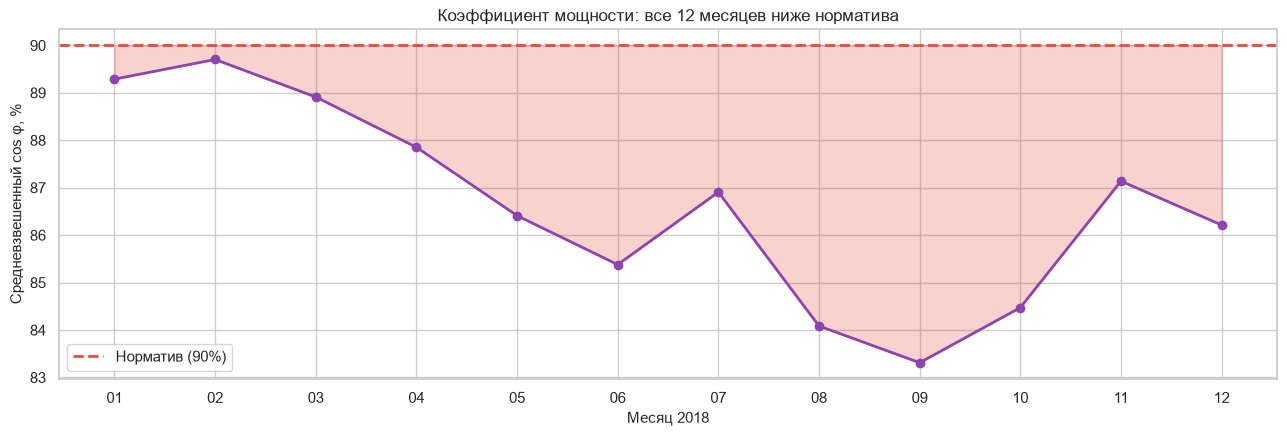

Месяц | cos φ, % | Макс. мощность, кВт
         cos_ср  макс_кВт
ym                       
2018-01   89.30    612.60
2018-02   89.70    582.00
2018-03   88.90    605.20
2018-04   87.90    556.10
2018-05   86.40    560.20
2018-06   85.40    535.40
2018-07   86.90    486.70
2018-08   84.10    534.80
2018-09   83.30    510.50
2018-10   84.50    557.70
2018-11   87.10    628.70
2018-12   86.20    596.70

Средний cos φ за год:    86.6%
Месяцев ниже нормы:      12 из 12
Худший месяц:            2018-09 (83.3%)
Надбавка за год:         2.98 млн вон
СЧЁТ ИТОГО, млн вон:     199.5
Чувствительность:        0.92 млн вон (если надбавка только к плате за мощность)


In [19]:
переменные_есть(['мес','df','счёт_база'])

# ---------- Истинный cos φ ----------
# В каждый момент содержательный только один из двух столбцов cos φ,
# поэтому считаем заново: P / sqrt(P^2 + Q^2), Q = обе реактивные составляющие.
Q = df['Lagging_Current_Reactive.Power_kVarh'] + df['Leading_Current_Reactive_Power_kVarh']
df['cos_phi'] = df['Usage_kWh'] / np.sqrt(df['Usage_kWh']**2 + Q**2) * 100
df.loc[df['Usage_kWh'] < 0.1, 'cos_phi'] = np.nan
проверить(df['cos_phi'].notna().sum() > 0, "cos_phi не посчитался")

# ---------- Помесячный средневзвешенный cos φ и надбавка ----------
v = df.dropna(subset=['cos_phi'])
мес['cos_ср'] = v.groupby('ym').apply(lambda g: np.average(g['cos_phi'], weights=g['Usage_kWh']))
проверить(мес['cos_ср'].notna().all(), "в каком-то месяце не посчитался cos φ")
мес['надбавка_%'] = (90 - мес['cos_ср']) * 0.5          # механизм KEPCO: 0,5% за 1%
мес['база']       = мес['по_энергии'] + мес['по_мощности']
мес['надбавка']   = мес['база'] * мес['надбавка_%'] / 100

итог_надбавка = мес['надбавка'].sum()
счёт_итог     = счёт_база + итог_надбавка
чувств        = (мес['по_мощности'] * мес['надбавка_%'] / 100).sum()  # если надбавка только к плате за мощность

# ---------- График ----------
fig, ax = plt.subplots()
xs = range(1, len(мес)+1)
ax.plot(xs, мес['cos_ср'].values, marker='o', lw=2, color='#8e44ad')
ax.axhline(90, color='#e74c3c', ls='--', lw=2, label='Норматив (90%)')
ax.fill_between(xs, мес['cos_ср'].values, 90, where=(мес['cos_ср'].values < 90),
                alpha=0.25, color='#e74c3c')
ax.set_xticks(list(xs)); ax.set_xticklabels([str(m)[-2:] for m in мес.index])
ax.set_xlabel('Месяц 2018'); ax.set_ylabel('Средневзвешенный cos φ, %')
ax.set_title('Коэффициент мощности: все 12 месяцев ниже норматива')
ax.legend(); plt.tight_layout(); plt.show()

print("Месяц | cos φ, % | Макс. мощность, кВт")
print(мес[['cos_ср','макс_кВт']].round(1).to_string())
print(f"\nСредний cos φ за год:    {мес['cos_ср'].mean():.1f}%")
print(f"Месяцев ниже нормы:      {(мес['cos_ср'] < 90).sum()} из 12")
print(f"Худший месяц:            {мес['cos_ср'].idxmin()} ({мес['cos_ср'].min():.1f}%)")
print(f"Надбавка за год:         {итог_надбавка/1e6:.2f} млн вон")
print(f"СЧЁТ ИТОГО, млн вон:     {счёт_итог/1e6:.1f}")
print(f"Чувствительность:        {чувств/1e6:.2f} млн вон (если надбавка только к плате за мощность)")

### Вывод по шагу 2: коэффициент мощности

**Все 12 месяцев cos φ ниже норматива 90%.** Средний за год — **86,6%**:
это значит, что около 13% прокачиваемой по проводам мощности не совершает
полезной работы, и завод доплачивает за это.

| Показатель | Значение |
|---|---|
| Средний cos φ за год | **86,6%** |
| Лучшие месяцы (январь–февраль) | **89,3–89,7%** |
| Худший месяц (сентябрь) | **83,3%** |
| Надбавка за год | **2,98 млн вон** |
| Чувствительность механизма | **0,94 млн вон**, если надбавка начисляется только на плату за мощность |

**Помесячно cos φ:** янв 89,3 · фев 89,7 · мар 88,9 · апр 87,9 · май 86,4 ·
июн 85,4 · июл 86,9 · авг 84,1 · сен 83,3 · окт 84,5 · ноя 87,1 · дек 86,2.

**Физика просадки:** в лёгких и пусковых режимах активная мощность мала,
а реактивная мощность намагничивания двигателей почти постоянна —
«пены в стакане» становится больше доли. По строкам данных cos φ в ночных
лёгких режимах опускается до 45–80%, в рабочих держится 88–99%.

> **Вывод для заказчика:** компенсаторы (УКРМ) нужно включать не «вообще»,
> а адресно — в лёгких и пусковых режимах, где просадка максимальна.

## Шаг 3: Пики и перенос нагрузки во времени

**Пояснения к показателям шага:**

- **Пик нагрузки** — интервалы с максимальной мощностью. Пик опасен дважды:
  он попадает в дорогую тарифную зону и фиксирует месячный максимум,
  от которого считается плата за мощность.
- **Перенос нагрузки во времени** — сдвиг энергоемких операций из пиковой зоны
  в ночную: та же работа, но по дешёвому тарифу и без фиксации максимума.
- **Тепловая карта** — среднее потребление по часам и дням недели:
  показывает, где именно живут пики.

**Что делаем:** считаем спред цен зон; моделируем сценарии переноса;
строим тепловую карту и профиль нагрузки.

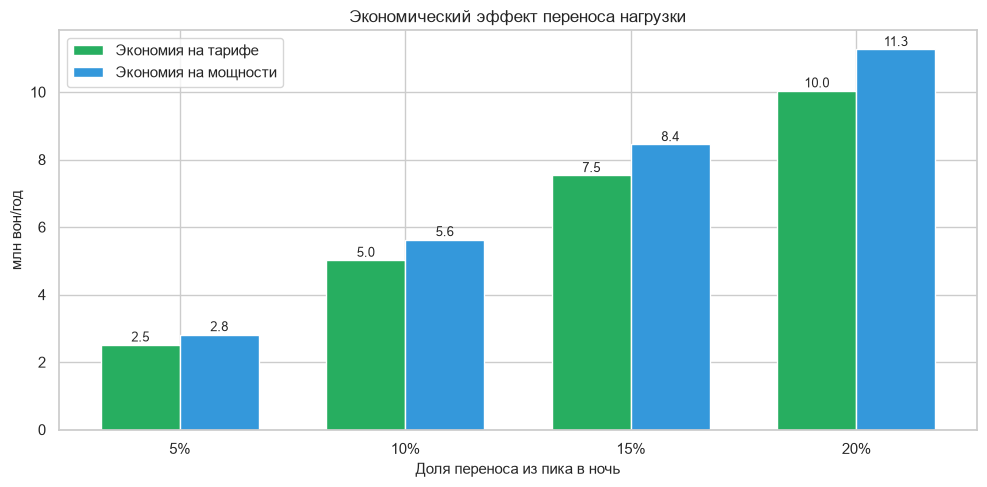

Доля    кВт_ч  Энергия  Мощность  Итого
  5% 19250.80     2.50      2.80   5.30
 10% 38501.60     5.00      5.60  10.60
 15% 57752.30     7.50      8.40  16.00
 20% 77003.10    10.00     11.30  21.30


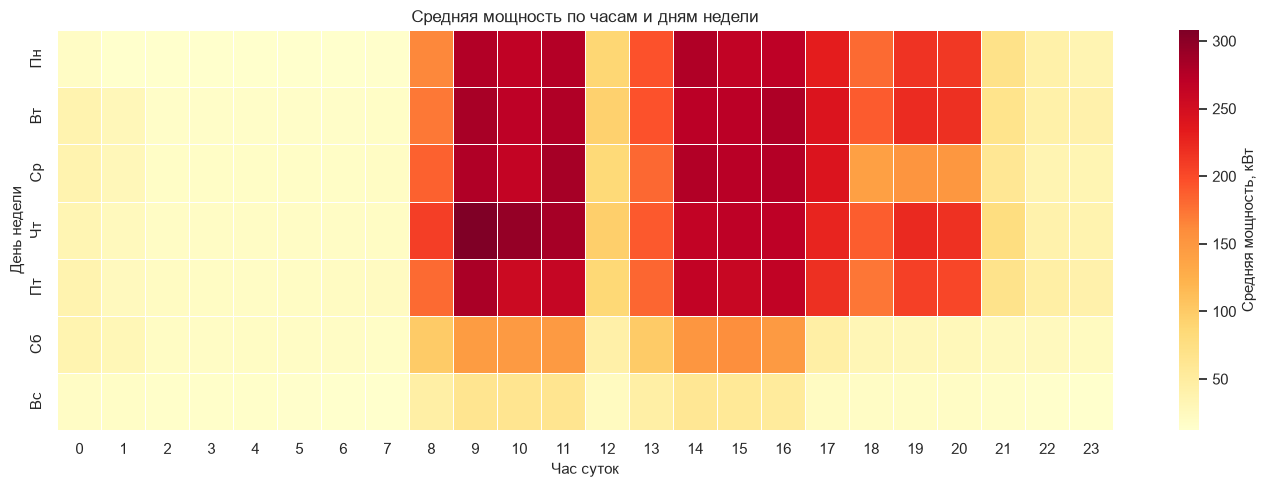


Спред пик/ночь: ×2.81 = 130.3 вон/кВт·ч
95% интервалов ниже, кВт: 396
99% интервалов ниже, кВт: 491
Максимум карты: Чт 9:00 → 308 кВт
Минимум карты:  Пн 6:00 → 12.6 кВт
Будни / выходные, кВт: 134 / 47 (−65%)


In [20]:
переменные_есть(['мес','df','зоны','ТАРИФ_МОЩНОСТЬ','дн'])

пик  = df[df['Зона'] == 'Пиковая']
ночь = df[df['Зона'] == 'Ночная']
тариф_пик  = пик['Стоимость'].sum()  / пик['Usage_kWh'].sum()
тариф_ночь = ночь['Стоимость'].sum() / ночь['Usage_kWh'].sum()
спред = тариф_пик - тариф_ночь

# ---------- Сценарии переноса ----------
строки = []
for доля in [0.05, 0.10, 0.15, 0.20]:
    к  = пик['Usage_kWh'].sum() * доля
    эк = к * спред                                  # экономия на тарифе
    эм = мес['макс_кВт'].sum() * доля * ТАРИФ_МОЩНОСТЬ  # снижение платы за мощность
    строки.append({'Доля': f"{доля*100:.0f}%", 'кВт_ч': к,
                   'Энергия': эк/1e6, 'Мощность': эм/1e6, 'Итого': (эк+эм)/1e6})
табл = pd.DataFrame(строки)
проверить(len(табл) == 4 and (табл['Итого'] > 0).all(), "таблица сценариев неполная")
реалистичный = табл[табл['Доля'] == '10%']['Итого'].values[0] * 1e6

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(табл)); ш = 0.35
b1 = ax.bar([i-ш/2 for i in x], табл['Энергия'], ш, label='Экономия на тарифе', color='#27ae60')
b2 = ax.bar([i+ш/2 for i in x], табл['Мощность'], ш, label='Экономия на мощности', color='#3498db')
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.1, f'{b.get_height():.1f}',
            ha='center', fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels(табл['Доля'])
ax.set_xlabel('Доля переноса из пика в ночь'); ax.set_ylabel('млн вон/год')
ax.set_title('Экономический эффект переноса нагрузки'); ax.legend()
plt.tight_layout(); plt.show()
print(табл.round(1).to_string(index=False))

# ---------- Тепловая карта в киловаттах ----------
карта = df.pivot_table(values='кВт', index='dow', columns='hour', aggfunc='mean')
карта.index = дн
plt.figure(figsize=(14, 5))
sns.heatmap(карта, cmap='YlOrRd', linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'Средняя мощность, кВт'})
plt.title('Средняя мощность по часам и дням недели')
plt.xlabel('Час суток'); plt.ylabel('День недели')
plt.tight_layout(); plt.show()

всего = карта.stack()
макс_слот, мин_слот = всего.idxmax(), всего.idxmin()
будни = df[df['WeekStatus']=='Weekday']['кВт'].mean()
вых   = df[df['WeekStatus']=='Weekend']['кВт'].mean()

print(f"\nСпред пик/ночь: ×{тариф_пик/тариф_ночь:.2f} = {спред:.1f} вон/кВт·ч")
print(f"95% интервалов ниже, кВт: {df['кВт'].quantile(0.95):.0f}")
print(f"99% интервалов ниже, кВт: {df['кВт'].quantile(0.99):.0f}")
print(f"Максимум карты: {макс_слот[0]} {макс_слот[1]}:00 → {всего.max():.0f} кВт")
print(f"Минимум карты:  {мин_слот[0]} {мин_слот[1]}:00 → {всего.min():.1f} кВт")
print(f"Будни / выходные, кВт: {будни:.0f} / {вых:.0f} (−{(1-вых/будни)*100:.0f}%)")

### Вывод по шагу 3: пики и перенос нагрузки во времени

**Профиль нагрузки (в киловаттах средней мощности интервала):**

| Показатель | Значение |
|---|---|
| Абсолютный максимум | **628,7 кВт** |
| 95% интервалов | ниже **396 кВт** |
| 99% интервалов | ниже **491 кВт** |
| Будни / выходные (среднее) | **134 кВт** / **47 кВт** (−65%) |
| Максимум тепловой карты | **четверг, 09:00 → 308 кВт** |
| Минимум тепловой карты | **понедельник, 06:00 → 12,6 кВт** |
| Разброс пик/минимум | **×24,5** |

Потребление сосредоточено в будних часах 08:00–18:00; ночь 23:00–06:00
практически свободна — это резерв для переноса.

**Экономический эффект переноса нагрузки из пиковой зоны в ночную:**

| Доля переноса | Объём, кВт·ч | Экономия на тарифе | Экономия на мощности | Итого |
|---|---|---|---|---|
| 5% | 19 251 | 2,5 млн вон | 2,8 млн вон | **5,3 млн вон** |
| **10%** | **38 502** | **5,0 млн вон** | **5,6 млн вон** | **10,6 млн вон** |
| 15% | 57 752 | 7,5 млн вон | 8,4 млн вон | **16,0 млн вон** |
| 20% | 77 003 | 10,0 млн вон | 11,3 млн вон | **21,3 млн вон** |

**Реалистичный сценарий — 10%: 10,6 млн вон в год (5,3% счёта).**
Обратите внимание: половина эффекта приходит не от тарифа, а от снижения
месячных максимумов, то есть от платы за мощность.

> **Ограничение:** экономия на плате за мощность реализуется только если
> перенос действительно снижает месячный максимум; проверку по месяцам
> выносим в следующий этап.

## Шаг 4: Аудит штатной метки нагрузки

**Пояснения к показателям шага:**

- **Load_Type** — класс нагрузки, который присваивает система учёта:
  лёгкая / средняя / максимальная. На него опираются отчёты и, потенциально,
  модели прогнозирования.
- **Фактический класс** — класс, пересчитанный нами по фактической мощности:
  лёгкая < 40 кВт, средняя 40–240 кВт, максимальная > 240 кВт.
- **Матрица расхождений** — таблица «метка против факта»: показывает,
  где система учёта ошибается.

**Что делаем:** сравниваем метку с фактом; выделяем критический случай
(метка «лёгкая» при мощности выше 240 кВт); ищем, когда это происходит.

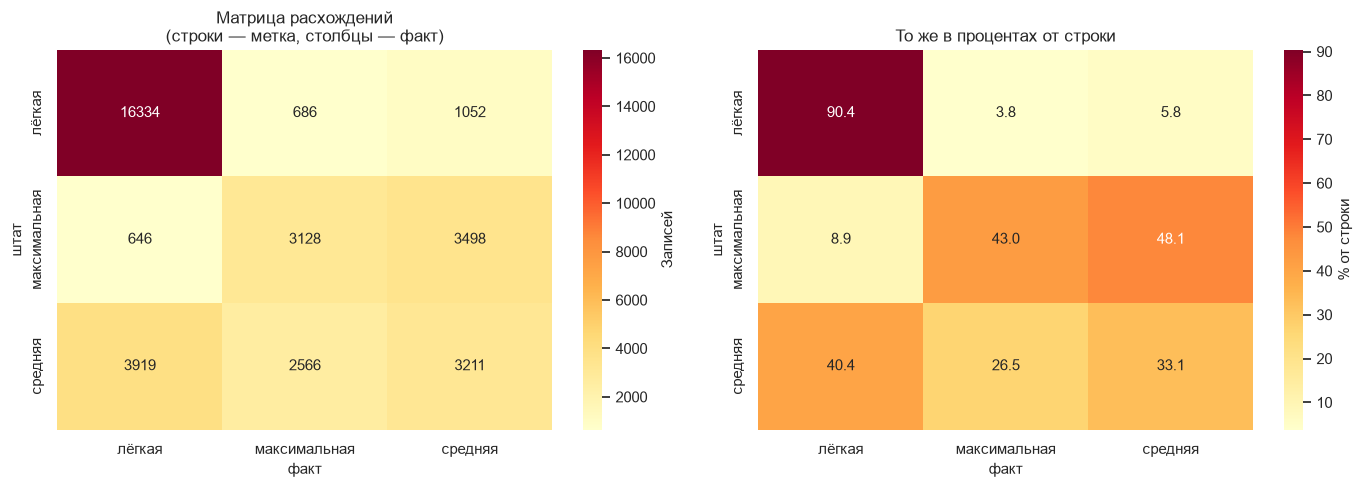

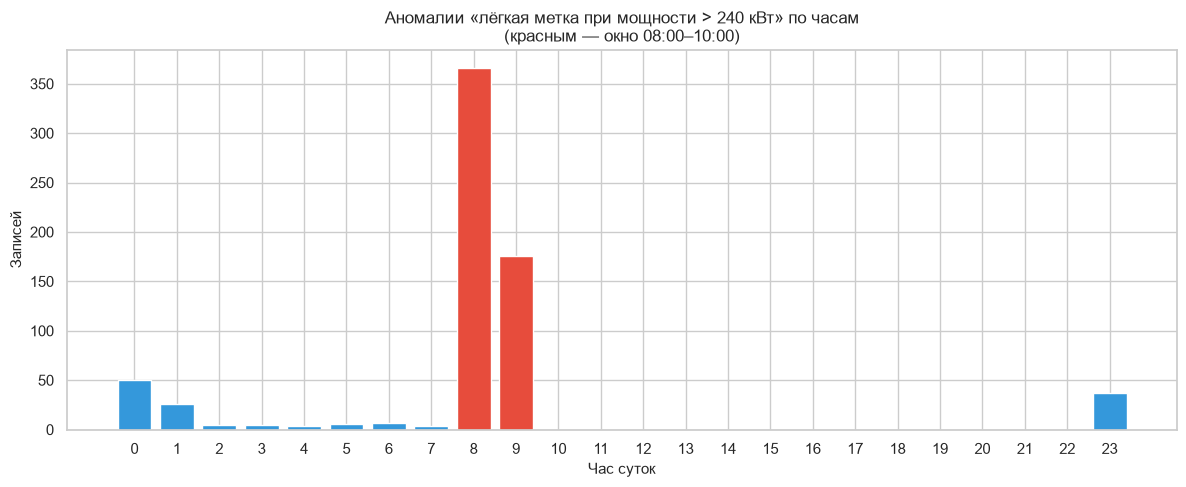

Расхождение метки с фактом: 12,367 из 35,040 = 35.3%
факт          лёгкая  максимальная  средняя
штат                                       
лёгкая         16334           686     1052
максимальная     646          3128     3498
средняя         3919          2566     3211

Записей «лёгкая» при >240 кВт: 686
Максимум среди них, кВт:       561
Суммарно, кВт·ч:               58,029 (6.0% года)
Их стоимость, млн вон:         4.95
В окне 08:00–10:00:            542 (79%)
Средний cos φ в аномалиях:     84.6%
По дням недели: Пн=95, Вт=121, Ср=116, Чт=146, Пт=127, Сб=64, Вс=17


In [21]:
переменные_есть(['df','дн'])

def фактический(квт):
    if квт < 40:  return 'лёгкая'
    if квт <= 240: return 'средняя'
    return 'максимальная'
df['факт'] = df['кВт'].apply(фактический)
df['штат'] = df['Load_Type'].map({'Light_Load':'лёгкая','Medium_Load':'средняя',
                                  'Maximum_Load':'максимальная'})
расх = (df['штат'] != df['факт']).sum()

матрица = pd.crosstab(df['штат'], df['факт'])
проверить(матрица.sum().sum() == len(df), "матрица покрыла не все записи")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(матрица, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0],
            cbar_kws={'label': 'Записей'})
axes[0].set_title('Матрица расхождений\n(строки — метка, столбцы — факт)')
мп = матрица.div(матрица.sum(axis=1), axis=0) * 100
sns.heatmap(мп, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1],
            cbar_kws={'label': '% от строки'})
axes[1].set_title('То же в процентах от строки')
plt.tight_layout(); plt.show()

# ---------- Критический случай ----------
аном = df[(df['штат'] == 'лёгкая') & (df['кВт'] > 240)]
проверить(len(аном) > 0, "аномалий не найдено — проверь порог 240 кВт")
Qa = аном['Lagging_Current_Reactive.Power_kVarh'] + аном['Leading_Current_Reactive_Power_kVarh']
pf_ан = (аном['Usage_kWh'] / np.sqrt(аном['Usage_kWh']**2 + Qa**2) * 100).mean()
аном_ст = (аном['Usage_kWh'] * аном['Тариф']).sum()
окно = аном[аном['hour'].isin([8,9])].shape[0]

fig, ax = plt.subplots(figsize=(12, 5))
по_часам = аном.groupby('hour').size()
цвета = ['#e74c3c' if h in (8,9) else '#3498db' for h in range(24)]
ax.bar(range(24), [по_часам.get(h,0) for h in range(24)], color=цвета)
ax.set_xticks(range(24)); ax.set_xlabel('Час суток')
ax.set_ylabel('Записей'); ax.set_title('Аномалии «лёгкая метка при мощности > 240 кВт» по часам\n(красным — окно 08:00–10:00)')
plt.tight_layout(); plt.show()

print(f"Расхождение метки с фактом: {расх:,} из {len(df):,} = {расх/len(df)*100:.1f}%")
print(матрица.to_string())
print(f"\nЗаписей «лёгкая» при >240 кВт: {len(аном)}")
print(f"Максимум среди них, кВт:       {аном['кВт'].max():.0f}")
print(f"Суммарно, кВт·ч:               {аном['Usage_kWh'].sum():,.0f} "
      f"({аном['Usage_kWh'].sum()/df['Usage_kWh'].sum()*100:.1f}% года)")
print(f"Их стоимость, млн вон:         {аном_ст/1e6:.2f}")
print(f"В окне 08:00–10:00:            {окно} ({окно/len(аном)*100:.0f}%)")
print(f"Средний cos φ в аномалиях:     {pf_ан:.1f}%")
по_дням = аном.groupby('dow').size()
print("По дням недели:", ', '.join(f"{дн[i]}={по_дням.get(i,0)}" for i in range(7)))

### Вывод по шагу 4: штатная метка нагрузки ошибочна в 35,3% случаев

**Это самая важная находка разбора.**

| Класс в данных | Записей | Медиана мощности | Максимум мощности |
|---|---|---|---|
| Лёгкая нагрузка | 18 072 | 13,2 кВт | **561 кВт** |
| Средняя нагрузка | 9 696 | 137,8 кВт | **629 кВт** |
| Максимальная нагрузка | 7 272 | 226,5 кВт | 607 кВт |

Диапазоны перекрываются полностью: «лёгкая» метка встречается и при 561 кВт.

**Матрица расхождений** (строки — метка, столбцы — факт):

| | факт: лёгкая | факт: средняя | факт: максимальная |
|---|---|---|---|
| метка: лёгкая | 16 334 | 1 052 | **686** |
| метка: средняя | 3 919 | 3 211 | 2 566 |
| метка: максимальная | 646 | 3 498 | 3 128 |

**Итого неверны 12 367 записей из 35 040 = 35,3%.**

Критический случай: **686 записей с меткой «лёгкая» при мощности выше 240 кВт**
(вплоть до 561 кВт). Это **6,0% годового потребления** на сумму **4,95 млн вон**.
**542 записи из 686 (79%)** попадают в окно **08:00–10:00**;
по дням: пн=95, вт=121, ср=116, чт=146, пт=127, сб=64, вс=17.

> ### Диагноз
> Это **утренний пусковой разгон**: пусковые токи двигателей в несколько раз
> выше номинала, а классификатор обновляет метку с запозданием.
> Средний cos φ в этих записях — **84,6%**: пуск одновременно создаёт пик
> мощности и просаживает коэффициент мощности.

> ### Рекомендации
> 1. Не использовать `Load_Type` ни как признак, ни как цель модели.
> 2. Внедрить плавный пуск (устройства плавного пуска, частотные преобразователи).
> 3. Включать компенсаторы до начала разгона (≈ 07:45).

## Шаг 5: Углеродный след

**Пояснения к показателям шага:**

- **CO₂ (т)** — масса углекислого газа, приходящаяся на выработку потреблённой
  энергии. В «честном» датасете это менялась бы по часам (ночью сеть чище —
  больше АЭС и ГЭС, днём грязнее — уголь и газ).
- **Утечка целевого признака** — ситуация, когда признак содержит в себе ответ
  (здесь: CO₂ пересчитан из потребления). Модель на таком признаке учится
  «подглядывать», а не прогнозировать.

**Что делаем:** проверяем, самостоятелен ли CO₂ или это производная;
оцениваем снижение выбросов от переноса нагрузки.

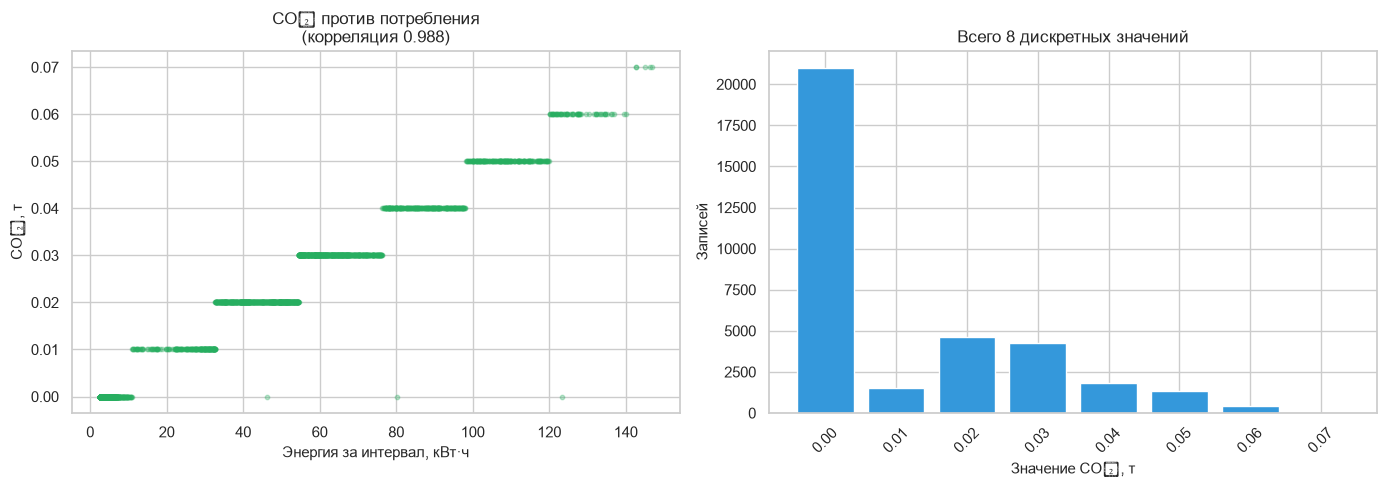

CO₂ за год, т:                403.81
Уникальных значений:          8 → ['0.00', '0.01', '0.02', '0.03', '0.04', '0.05', '0.06', '0.07']
Корреляция с потреблением:    0.9882
Интенсивность, т/кВт·ч:       0.00042
Снижение CO₂ при переносе 10% пика, т/год: 16.2


In [22]:
переменные_есть(['df','пик'])

уникальных = sorted(df['CO2(tCO2)'].unique())
корр = df[['Usage_kWh','CO2(tCO2)']].corr().iloc[0,1]
интенсивность = df['CO2(tCO2)'].sum() / df['Usage_kWh'].sum()
со2_экономия  = пик['Usage_kWh'].sum() * 0.10 * интенсивность

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
выб = df.sample(n=min(5000, len(df)), random_state=42)
axes[0].scatter(выб['Usage_kWh'], выб['CO2(tCO2)'], alpha=0.3, s=10, c='#27ae60')
axes[0].set_xlabel('Энергия за интервал, кВт·ч'); axes[0].set_ylabel('CO₂, т')
axes[0].set_title(f'CO₂ против потребления\n(корреляция {корр:.3f})')
axes[1].bar([f'{v:.2f}' for v in уникальных],
            [(df['CO2(tCO2)']==v).sum() for v in уникальных], color='#3498db')
axes[1].set_xlabel('Значение CO₂, т'); axes[1].set_ylabel('Записей')
axes[1].set_title('Всего 8 дискретных значений'); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

print(f"CO₂ за год, т:                {df['CO2(tCO2)'].sum():.2f}")
print(f"Уникальных значений:          {len(уникальных)} → {[f'{v:.2f}' for v in уникальных]}")
print(f"Корреляция с потреблением:    {корр:.4f}")
print(f"Интенсивность, т/кВт·ч:       {интенсивность:.5f}")
print(f"Снижение CO₂ при переносе 10% пика, т/год: {со2_экономия:.1f}")

### Вывод по шагу 5: что можно и чего нельзя сказать про углеродный след

| Показатель | Значение |
|---|---|
| Выбросы CO₂ за год | **403,81 т** |
| Уникальных значений | **8** (от 0,00 до 0,07 т) |
| Корреляция с потреблением | **0,988** |
| Интенсивность | **0,00042 т/кВт·ч** (постоянна) |

**Разбор:** восемь дискретных значений и корреляция 0,988 означают, что CO₂ —
расчётная производная от потребления, а не замер углеродоёмкости сети.

**Следствия:**

1. **Нельзя использовать CO₂ как признак модели** — это утечка целевого
   признака (совпадает с выводом технического разбора).
2. **Нельзя строить «зелёное расписание»**: углеродоёмкость сети в данных
   не меняется по часам. Нужны внешние данные о составе генерации.
3. **Можно использовать как отчётный показатель:** перенос 38 502 кВт·ч
   (сценарий 10%) даёт **−16,2 т CO₂ в год**.

> Углеродная оптимизация по часам суток на этих данных невозможна; CO₂ используем только как отчётный показатель экономии.

## Шаг 6: Итоговая сводка резервов экономии

**Что делаем:** собираем подтверждённые резервы в одну таблицу, формулируем
главные находки, ограничения и план внедрения.

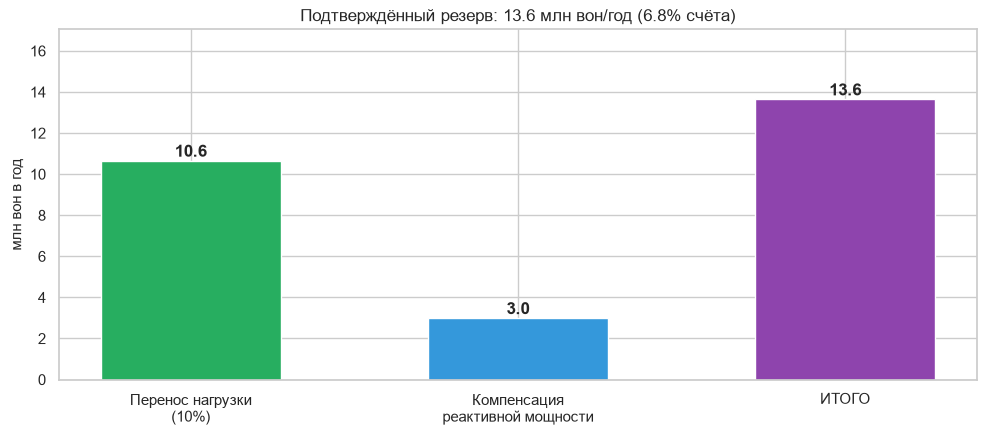

Перенос нагрузки (10%):     10.6 млн вон/год
Компенсация реактивной:     2.98 млн вон/год
ПОДТВЕРЖДЕНО ИТОГО:         13.6 млн вон/год (6.8% счёта)
Зона аудита (утренний пуск): до 4.95 млн вон/год
Снижение выбросов:          16.2 т CO₂/год


In [23]:
переменные_есть(['реалистичный','итог_надбавка','аном_ст','счёт_итог','со2_экономия'])

перенос_10  = реалистичный
компенсация = итог_надбавка
аудит       = аном_ст
всего_подтв = перенос_10 + компенсация

fig, ax = plt.subplots(figsize=(10, 4.5))
кат = ['Перенос нагрузки\n(10%)', 'Компенсация\nреактивной мощности', 'ИТОГО']
знач = [перенос_10/1e6, компенсация/1e6, всего_подтв/1e6]
б = ax.bar(кат, знач, color=['#27ae60','#3498db','#8e44ad'], width=0.55)
for с, з in zip(б, знач):
    ax.text(с.get_x()+с.get_width()/2, з+0.2, f'{з:.1f}', ha='center',
            fontweight='bold', fontsize=12)
ax.set_ylabel('млн вон в год'); ax.set_ylim(0, max(знач)*1.25)
ax.set_title(f'Подтверждённый резерв: {всего_подтв/1e6:.1f} млн вон/год '
             f'({всего_подтв/счёт_итог*100:.1f}% счёта)')
plt.tight_layout(); plt.show()

print(f"Перенос нагрузки (10%):     {перенос_10/1e6:.1f} млн вон/год")
print(f"Компенсация реактивной:     {компенсация/1e6:.2f} млн вон/год")
print(f"ПОДТВЕРЖДЕНО ИТОГО:         {всего_подтв/1e6:.1f} млн вон/год "
      f"({всего_подтв/счёт_итог*100:.1f}% счёта)")
print(f"Зона аудита (утренний пуск): до {аудит/1e6:.2f} млн вон/год")
print(f"Снижение выбросов:          {со2_экономия:.1f} т CO₂/год")

## Итоговые выводы экономического разбора

### 1. Опорные показатели предприятия

| Показатель | Значение |
|---|---|
| Потребление за год | **959 637 кВт·ч** |
| Счёт за год | **199,5 млн вон** |
| Максимум 15-мин мощности | **628,7 кВт** |
| Средний cos φ | **86,6%** (ниже нормы все 12 месяцев) |
| Выбросы CO₂ | **403,8 т** |

### 2. Подтверждённые резервы экономии

| № | Механизм | Эффект | Статус |
|---|---|---|---|
| 1 | **Перенос нагрузки во времени** — 10% пикового объёма (38 502 кВт·ч) в ночную зону | **10,6 млн вон/год** | подтверждено расчётом |
| 2 | **Компенсация реактивной мощности** — доведение cos φ с 86,6% до 90% | **2,98 млн вон/год** | подтверждено (чувствительность 0,94 млн) |
| 3 | **Обследование утреннего пуска** (окно 08:00–10:00, 686 записей) | до 4,95 млн вон/год | зона обследования |
| | **Подтверждённый итог (п. 1 + п. 2)** | **13,6 млн вон/год = 6,8% счёта** | |

Дополнительно: **−16,2 т CO₂ в год**.

### 3. Три главные находки

**Находка 1. Метка нагрузки ошибочна в 35,3% случаев;** 686 записей «лёгкой»
нагрузки фактически шли с мощностью выше 240 кВт, 79% из них — в окне
утреннего пуска 08:00–10:00.

**Находка 2. 40% объёма дают 56% стоимости
энергии:** пик 202,3 вон/кВт·ч против ночи 71,9 (×2,81); плюс плата за мощность
реагирует на каждый часовой максимум месяца.

**Находка 3. cos φ ниже нормы круглый год:** просадка сосредоточена в лёгких
и пусковых режимах (45–80% против 88–99% в рабочих).

### 4. Ограничения разбора

| Ограничение | Последствие |
|---|---|
| Трактовка `Usage_kWh`: энергия за 15 мин (единицы UCI), мощность = ×4 | Если читать столбец как средние кВт, плата за мощность и связанные резервы уменьшатся в 4 раза: мощность 14,1 млн вон, счёт 156,6 млн, резерв 8,7 млн (5,6%) |
| Тарифы и зоны — справочные, зоны едины для сезонов | абсолютные суммы — оценка; выводы устойчивы в процентах |
| Механизм надбавки за cos φ упрощён | приведена чувствительность (2,98 против 0,94 млн вон) |
| Нет паспорта оборудования | нельзя точно указать переносимые агрегаты |
| Один год наблюдений | сезонность не отделить от тренда; второе полугодие ниже на 15,9% |
| Малое предприятие | абсолютные суммы скромны; методика масштабируется |

### 5. Что предлагается внедрить

| Составная часть | Назначение | Эффект |
|---|---|---|
| Модель прогноза потребления | прогноз на 1–4 часа | основа решений |
| Система оповещений | сигнал за 30 минут до превышения порога | предотвращение пиков |
| Планировщик запусков | время включения агрегатов | перенос нагрузки, 10,6 млн вон |
| Контроль cos φ | управление компенсаторами в лёгких режимах | 2,98 млн вон |
| Контролёр меток | автопроверка класса по факту | устранение 35% ошибок |
| Панель показателей | рабочее место энергетика | оперативные решения |

## Контрольная ячейка

Печатает все ключевые числа в одном месте. После `Run All` необходимо сверить вывод
с таблицами выше: любое расхождение означает, что текст устарел.

In [25]:
переменные_есть(['df','мес','счёт_база','счёт_итог','итог_энергия','итог_мощность',
                 'итог_надбавка','чувств','тариф_пик','тариф_ночь','перенос_10',
                 'всего_подтв','расх','аном','со2_экономия'])
print("Потребление за год, кВт·ч:       ", f"{df['Usage_kWh'].sum():,.0f}",  "| текст: 959 637")
print("Максимум 15-мин мощности, кВт:   ", f"{df['кВт'].max():.1f}",          "| текст: 628,7")
print("Плата за энергию, млн вон:       ", f"{итог_энергия/1e6:.1f}",          "| текст: 140,2")
print("Плата за мощность, млн вон:      ", f"{итог_мощность/1e6:.1f}",         "| текст: 56,3")
print("Надбавка за cos φ, млн вон:      ", f"{итог_надбавка/1e6:.2f}",         "| текст: 2,98")
print("Счёт итого, млн вон:             ", f"{счёт_итог/1e6:.1f}",             "| текст: 199,5")
print("Средний cos φ, %:                ", f"{мес['cos_ср'].mean():.1f}",       "| текст: 86,6")
print("Тариф пик / ночь, вон:           ", f"{тариф_пик:.1f} / {тариф_ночь:.1f}", "| текст: 202,3 / 71,9")
print("Перенос 10%, млн вон:            ", f"{перенос_10/1e6:.1f}",            "| текст: 10,6")
print("Подтверждённый резерв, млн вон: ", f"{всего_подтв/1e6:.1f}",            "| текст: 13,6")
print("Доля резерва от счёта, %:        ", f"{всего_подтв/счёт_итог*100:.1f}",  "| текст: 6,8")
print("Ошибочных меток, %:              ", f"{расх/len(df)*100:.1f}",          "| текст: 35,3")
print("Аномалий лёгкой метки, шт:       ", f"{len(аном)}",                     "| текст: 686")
print("  из них в окне 08:00–10:00:     ", f"{аном[аном['hour'].isin([8,9])].shape[0]}", "| текст: 542")
print("CO₂ за год, т:                   ", f"{df['CO2(tCO2)'].sum():.1f}",     "| текст: 403,8")
print("Снижение CO₂, т/год:             ", f"{со2_экономия:.1f}",              "| текст: 16,2")
print("\nСверка завершена. При расхождениях необходимо обновить markdown-ячейки.")

Потребление за год, кВт·ч:        959,637 | текст: 959 637
Максимум 15-мин мощности, кВт:    628.7 | текст: 628,7
Плата за энергию, млн вон:        140.2 | текст: 140,2
Плата за мощность, млн вон:       56.3 | текст: 56,3
Надбавка за cos φ, млн вон:       2.98 | текст: 2,98
Счёт итого, млн вон:              199.5 | текст: 199,5
Средний cos φ, %:                 86.6 | текст: 86,6
Тариф пик / ночь, вон:            202.3 / 71.9 | текст: 202,3 / 71,9
Перенос 10%, млн вон:             10.6 | текст: 10,6
Подтверждённый резерв, млн вон:  13.6 | текст: 13,6
Доля резерва от счёта, %:         6.8 | текст: 6,8
Ошибочных меток, %:               35.3 | текст: 35,3
Аномалий лёгкой метки, шт:        686 | текст: 686
  из них в окне 08:00–10:00:      542 | текст: 542
CO₂ за год, т:                    403.8 | текст: 403,8
Снижение CO₂, т/год:              16.2 | текст: 16,2

Сверка завершена. При расхождениях необходимо обновить markdown-ячейки.
